In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import ExtraTreesRegressor

In [2]:
df = pd.read_csv("model_cleaned_wo_listing_age.csv", delimiter=',' ,encoding='latin-1')

In [3]:
df.head()

,Unnamed: 0,dateCrawled,name,seller,price,abtest,vehicleType,yearOfRegistration,gearbox,powerPS,model,kilometer,monthOfRegistration,fuelType,brand,notRepairedDamage,listingAge,clean_model,clean_model_2,model_final
0,0,2016-03-14 12:52:21,"Jeep_Grand_Cherokee_""Overland""",privat,9800,test,suv,2004,automatik,163,grand,125000,8,diesel,jeep,NaN,22.533171,grand cherokee,grand cherokee,grand cherokee
1,1,2016-03-17 16:54:04,GOLF_4_1_4__3TÃÂRER,privat,1500,test,kleinwagen,2001,manuell,75,golf,150000,6,benzin,volkswagen,nein,0.736308,golf,golf,golf
2,2,2016-03-31 17:25:20,Skoda_Fabia_1.4_TDI_PD_Classic,privat,3600,test,kleinwagen,2008,manuell,69,fabia,90000,7,diesel,skoda,nein,6.428715,fabia,fabia,fabia
3,3,2016-04-04 17:36:23,BMW_316i___e36_Limousine___Bastlerfahrzeug__Ex...,privat,650,test,limousine,1995,manuell,102,3er,150000,10,benzin,bmw,ja,2.803553,316i,316i,316i
4,4,2016-04-01 20:48:51,Peugeot_206_CC_110_Platinum,privat,2200,test,cabrio,2004,manuell,109,2_reihe,150000,8,benzin,peugeot,nein,4.762951,206,206,206


In [4]:
counts = df["model_final"].value_counts()
valid_models = counts[counts >= 10].index
df = df[df["model_final"].isin(valid_models)]
df = df[df["model_final"] != "other"]


In [37]:
X = df.drop(columns=["seller", "abtest", "name", "clean_model", "clean_model_2", "model", "dateCrawled", "monthOfRegistration", "listingAge"])
X["car_age"] = 2026 - X.yearOfRegistration
X = X.drop(columns = "yearOfRegistration")
X.to_csv("models_cleaned_over_10_instances.csv", )


X = X.drop(columns="price")
X = X.drop(df.columns[0], axis=1)
y = df["price"]

In [38]:
X.head()


,vehicleType,gearbox,powerPS,kilometer,fuelType,brand,notRepairedDamage,model_final,car_age
0,suv,automatik,163,125000,diesel,jeep,NaN,grand cherokee,22
1,kleinwagen,manuell,75,150000,benzin,volkswagen,nein,golf,25
2,kleinwagen,manuell,69,90000,diesel,skoda,nein,fabia,18
3,limousine,manuell,102,150000,benzin,bmw,ja,316i,31
4,cabrio,manuell,109,150000,benzin,peugeot,nein,206,22


In [7]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Numeric: ['powerPS', 'kilometer']
Categorical: ['vehicleType', 'gearbox', 'fuelType', 'brand', 'notRepairedDamage', 'model_final']


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

In [9]:
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

In [10]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [11]:
'''
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=20,
        sparse_output=False
    ))
])
'''

'\ncategorical_transformer = Pipeline(steps=[\n    ("imputer", SimpleImputer(\n        strategy="constant",\n        fill_value="unknown"\n    )),\n    ("encoder", OneHotEncoder(\n        handle_unknown="infrequent_if_exist",\n        min_frequency=20,\n        sparse_output=False\n    ))\n])\n'

In [15]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="constant",
                              fill_value="unknown")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20,
        sparse_output=False
    ))
])

In [16]:
from sklearn.ensemble import HistGradientBoostingRegressor
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        random_state=42,
        learning_rate=0.03,
        max_iter=400,       # vastab n_estimators-ile
        max_leaf_nodes=15,
        max_depth=3,
        min_samples_leaf=3,))
])

In [17]:
model.fit(X_train_2, y_train_2)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['vehicleType','gearbox','powerPS',...,'brand','notRepairedDamage', 'model_final']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subs

In [18]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = model.predict(X_test_2)

mae = mean_absolute_error(y_test_2, predictions)
rmse = np.sqrt(mean_squared_error(y_test_2, predictions))
r2 = r2_score(y_test_2, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 2317.2270387104227
RMSE: 3656.6406048454774
R²: 0.7751330384742211


In [19]:
model2 = Pipeline([
    ("preprocessor", preprocessor),

("Extra Trees", ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        n_jobs=-1,
        random_state=42))
])

In [20]:
model2.fit(X_train_2, y_train_2)
predictions2 = model2.predict(X_test_2)

mae = mean_absolute_error(y_test_2, predictions2)
rmse = np.sqrt(mean_squared_error(y_test_2, predictions2))
r2 = r2_score(y_test_2, predictions2)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1591.9060246766496
RMSE: 2811.32495828549
R²: 0.8670821851597235


                                 feature  importance
0                           num__powerPS    0.331619
1                         num__kilometer    0.285782
14                  cat__fuelType_diesel    0.072032
5            cat__vehicleType_kleinwagen    0.039803
44                    cat__brand_porsche    0.035065
11                  cat__gearbox_manuell    0.033801
10                cat__gearbox_automatik    0.032027
57           cat__notRepairedDamage_nein    0.011061
19                       cat__brand_audi    0.010361
20                        cat__brand_bmw    0.006487
54                 cat__brand_volkswagen    0.006306
7             cat__vehicleType_limousine    0.005629
8                   cat__vehicleType_suv    0.005357
38              cat__brand_mercedes_benz    0.005341
3                cat__vehicleType_cabrio    0.005084
6                 cat__vehicleType_kombi    0.004294
585         cat__model_final_transporter    0.004181
274             cat__model_final_boxster    0.

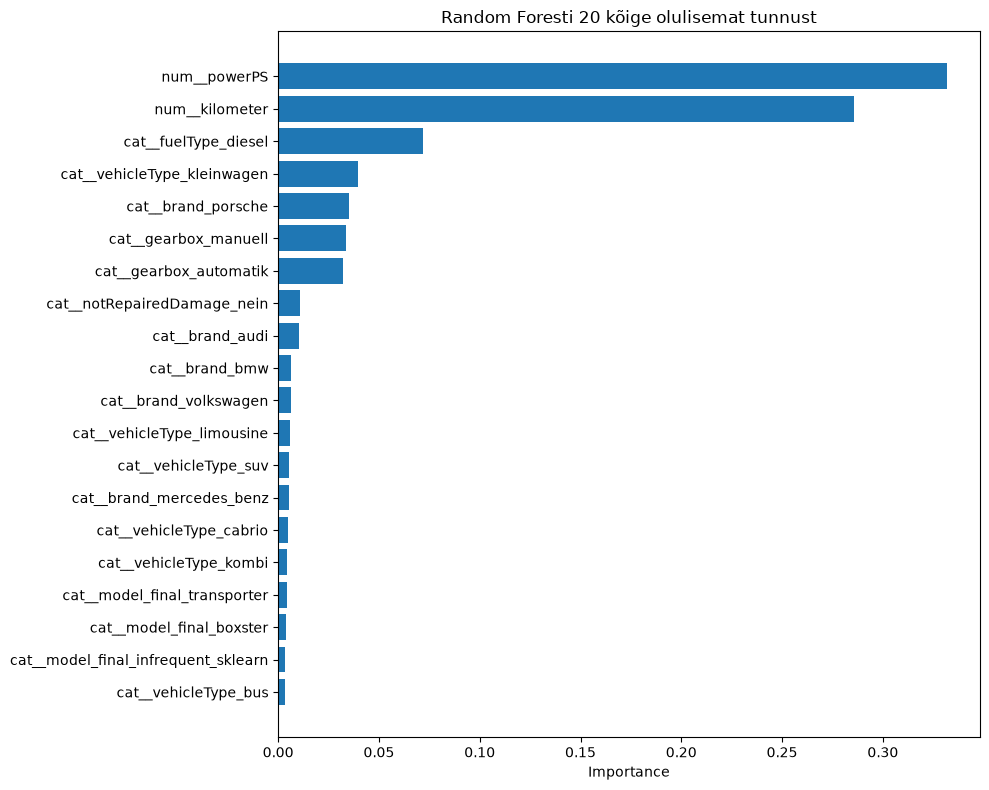

In [25]:
import matplotlib.pyplot as plt

# Võta mudelist eeltöödeldud tunnuste nimed
preprocessor = model2.named_steps["preprocessor"]
regressor = model2.named_steps["Extra Trees"]

feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": regressor.feature_importances_
})

importance = importance.sort_values("importance", ascending=False)

print(importance.head(20))

# Joonista graafik
top_features = importance.head(20).sort_values("importance")

plt.figure(figsize=(10, 8))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Importance")
plt.title("Random Foresti 20 kõige olulisemat tunnust")
plt.tight_layout()
plt.show()

In [26]:
errors = pd.DataFrame({
    "actual": y_test_2,
    "predicted": predictions
})

errors["absolute_error"] = (
    errors["actual"] - errors["predicted"]
).abs()

errors["price_group"] = pd.cut(
    errors["actual"],
    bins=[0, 3000, 7000, 15000, 30000, float("inf")],
    labels=["0-3000", "3000-7000", "7000-15000",
            "15000-30000", "30000+"]
)

print(
    errors.groupby("price_group", observed=True)
    .agg(
        MAE=("absolute_error", "mean"),
        car_count=("actual", "count")
    )
)

                      MAE  car_count
price_group                         
0-3000        1474.291667      16107
3000-7000     1824.047376      10873
7000-15000    2873.038286       8400
15000-30000   4599.888492       3563
30000+       11085.177424        700


In [28]:
errors = pd.DataFrame({
    "actual": y_test_2,
    "predicted": predictions
})

errors["absolute_error"] = abs(
    errors["actual"] - errors["predicted"]
)

print(
    errors.sort_values(
        "absolute_error",
        ascending=False
    ).head(20)
)

        actual     predicted  absolute_error
201149   82700  31706.479372    50993.520628
248685   92500  42043.148272    50456.851728
74690      790  48020.573999    47230.573999
185973   74999  28424.582770    46574.417230
242821   71500  26413.313806    45086.686194
129666   80900  37318.506080    43581.493920
174974   90000  46748.299561    43251.700439
172620    1642  44030.199154    42388.199154
91826    74500  33016.733529    41483.266471
5162     89000  50303.146085    38696.853915
131588   69450  31755.485505    37694.514495
238838    2999  39022.695294    36023.695294
94211    83990  48732.264144    35257.735856
99762    99999  64962.285668    35036.714332
213386   84900  50419.467216    34480.532784
79151    65000  31334.383973    33665.616027
154181    6666  40003.583107    33337.583107
83552    75990  42973.883981    33016.116019
159363   68000  35344.627925    32655.372075
232206   71500  39537.546624    31962.453376
